In [1]:
import json
import logging
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
ANOMALY_MODELS_DIR = PROJECT_ROOT / "models" / "anomaly" / "baseline_anomaly_models"

RANDOM_SEED = 42
FEATURE_CONFIGURATION = "log_amount_and_time_hours"

ISOLATION_FOREST_CONTAMINATION = 0.001
LOCAL_OUTLIER_FACTOR_CONTAMINATION = 0.001
LOCAL_OUTLIER_FACTOR_NEIGHBORS = 20

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANOMALY_MODELS_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Anomaly model directory: %s", ANOMALY_MODELS_DIR)

2026-11-01 10:48:56,787 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 10:48:56,789 | INFO | Anomaly model directory: c:\Users\use\Desktop\Credit Card Fraud Detection\models\anomaly\baseline_anomaly_models


In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


X_train, y_train = load_split(
    feature_path=DATA_PROCESSED_DIR / "train" / "X_train.parquet",
    target_path=DATA_PROCESSED_DIR / "train" / "y_train.parquet",
)

X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

X_train_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_train)
)

X_validation_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_validation)
)

if "Class" in X_train_engineered.columns or "Class" in X_validation_engineered.columns:
    raise ValueError("Target leakage detected in anomaly-detection features.")

if list(X_train_engineered.columns) != list(X_validation_engineered.columns):
    raise ValueError("Training and validation feature columns do not match.")

logger.info("Training features: %s", X_train_engineered.shape)
logger.info("Validation features: %s", X_validation_engineered.shape)
logger.info("Training fraud count: %s", int(y_train.sum()))
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 10:49:07,126 | INFO | Training features: (198608, 32)
2026-11-01 10:49:07,128 | INFO | Validation features: (42559, 32)
2026-11-01 10:49:07,132 | INFO | Training fraud count: 331
2026-11-01 10:49:07,134 | INFO | Validation fraud count: 71


In [4]:
def create_isolation_forest_pipeline() -> Pipeline:
    """Create an Isolation Forest anomaly-detection pipeline."""
    return Pipeline(
        steps=[
            (
                "isolation_forest",
                IsolationForest(
                    n_estimators=200,
                    max_samples="auto",
                    contamination=ISOLATION_FOREST_CONTAMINATION,
                    max_features=1.0,
                    random_state=RANDOM_SEED,
                    n_jobs=-1,
                ),
            ),
        ]
    )


def create_local_outlier_factor_pipeline() -> Pipeline:
    """Create a Local Outlier Factor novelty-detection pipeline."""
    return Pipeline(
        steps=[
            ("standard_scaler", StandardScaler()),
            (
                "local_outlier_factor",
                LocalOutlierFactor(
                    n_neighbors=LOCAL_OUTLIER_FACTOR_NEIGHBORS,
                    metric="minkowski",
                    contamination=LOCAL_OUTLIER_FACTOR_CONTAMINATION,
                    novelty=True,
                    n_jobs=-1,
                ),
            ),
        ]
    )


ANOMALY_EXPERIMENTS = {
    "Isolation Forest | Baseline": {
        "pipeline_factory": create_isolation_forest_pipeline,
        "preprocessing": "No scaling required",
        "score_direction": "Higher score means more anomalous",
    },
    "Local Outlier Factor | Baseline": {
        "pipeline_factory": create_local_outlier_factor_pipeline,
        "preprocessing": "StandardScaler fitted on training data only",
        "score_direction": "Higher score means more anomalous",
    },
}

logger.info("Defined anomaly-detection experiments: %s", list(ANOMALY_EXPERIMENTS))

2026-11-01 10:49:44,440 | INFO | Defined anomaly-detection experiments: ['Isolation Forest | Baseline', 'Local Outlier Factor | Baseline']


In [5]:
def evaluate_anomaly_predictions(
    y_true: pd.Series,
    anomaly_scores: np.ndarray,
    anomaly_predictions: np.ndarray,
) -> dict:
    """Evaluate anomaly predictions against available fraud labels."""
    confusion = confusion_matrix(y_true, anomaly_predictions, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    precision = precision_score(y_true, anomaly_predictions, zero_division=0)
    recall = recall_score(y_true, anomaly_predictions, zero_division=0)
    f1 = f1_score(y_true, anomaly_predictions, zero_division=0)

    false_positive_rate = (
        false_positive / (false_positive + true_negative)
        if (false_positive + true_negative) > 0
        else 0.0
    )

    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "pr_auc": float(average_precision_score(y_true, anomaly_scores)),
        "roc_auc": float(roc_auc_score(y_true, anomaly_scores)),
        "false_positive_rate": float(false_positive_rate),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }


def train_and_evaluate_anomaly_detector(
    experiment_name: str,
    pipeline_factory,
    preprocessing_description: str,
    score_direction: str,
    X_train: pd.DataFrame,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
) -> tuple[dict, Pipeline, np.ndarray, np.ndarray]:
    """Train an anomaly detector and evaluate its validation anomaly scores."""
    pipeline = pipeline_factory()

    training_start_time = time.time()
    pipeline.fit(X_train)
    training_duration = time.time() - training_start_time

    raw_validation_scores = pipeline.decision_function(X_validation)

    # Scikit-learn anomaly detectors use higher decision_function values for
    # normal observations. Reverse the sign so that higher values consistently
    # represent more anomalous transactions.
    anomaly_scores = -raw_validation_scores
    anomaly_predictions = pipeline.predict(X_validation)

    # Convert scikit-learn labels: -1 means anomaly, 1 means normal.
    anomaly_predictions = np.where(anomaly_predictions == -1, 1, 0)

    metrics = evaluate_anomaly_predictions(
        y_true=y_validation,
        anomaly_scores=anomaly_scores,
        anomaly_predictions=anomaly_predictions,
    )

    metrics.update(
        {
            "experiment_name": experiment_name,
            "model": experiment_name.split(" | ")[0],
            "feature_configuration": FEATURE_CONFIGURATION,
            "preprocessing": preprocessing_description,
            "score_direction": score_direction,
            "training_duration_seconds": training_duration,
            "feature_count": X_train.shape[1],
        }
    )

    return metrics, pipeline, anomaly_scores, anomaly_predictions


anomaly_results = []
trained_anomaly_pipelines = {}
anomaly_scores_by_experiment = {}
anomaly_predictions_by_experiment = {}

for experiment_name, experiment_definition in ANOMALY_EXPERIMENTS.items():
    logger.info("Training anomaly detector: %s", experiment_name)

    result, pipeline, anomaly_scores, anomaly_predictions = (
        train_and_evaluate_anomaly_detector(
            experiment_name=experiment_name,
            pipeline_factory=experiment_definition["pipeline_factory"],
            preprocessing_description=experiment_definition["preprocessing"],
            score_direction=experiment_definition["score_direction"],
            X_train=X_train_engineered,
            X_validation=X_validation_engineered,
            y_validation=y_validation,
        )
    )

    anomaly_results.append(result)
    trained_anomaly_pipelines[experiment_name] = pipeline
    anomaly_scores_by_experiment[experiment_name] = anomaly_scores
    anomaly_predictions_by_experiment[experiment_name] = anomaly_predictions

anomaly_results_dataframe = pd.DataFrame(anomaly_results)

anomaly_results_dataframe[
    [
        "experiment_name",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
        "training_duration_seconds",
    ]
]

2026-11-01 10:49:51,566 | INFO | Training anomaly detector: Isolation Forest | Baseline
2026-11-01 10:50:03,219 | INFO | Training anomaly detector: Local Outlier Factor | Baseline


,experiment_name,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives,training_duration_seconds
0,Isolation Forest | Baseline,0.222222,0.112676,0.149533,0.079585,0.933193,0.000659,36,28,63,9.197630
1,Local Outlier Factor | Baseline,0.000000,0.000000,0.000000,0.002650,0.514945,0.001106,47,47,71,135.385841


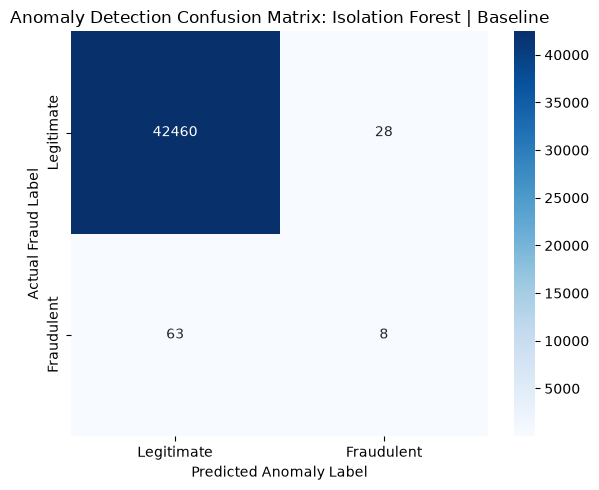

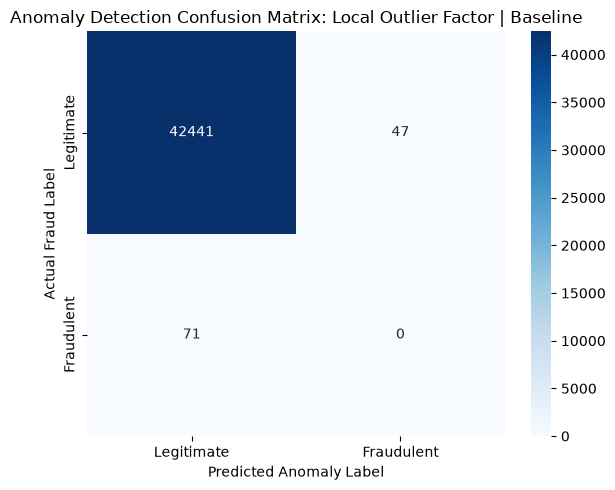

2026-11-01 10:53:39,715 | INFO | Anomaly-detection confusion matrices generated.


In [6]:
def plot_anomaly_confusion_matrix(
    y_true: pd.Series,
    anomaly_predictions: np.ndarray,
    title: str,
    output_path: Path,
) -> None:
    """Plot a confusion matrix for an anomaly detector."""
    confusion = confusion_matrix(y_true, anomaly_predictions, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"],
    )
    plt.title(title)
    plt.xlabel("Predicted Anomaly Label")
    plt.ylabel("Actual Fraud Label")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


for experiment_name, anomaly_predictions in anomaly_predictions_by_experiment.items():
    safe_experiment_name = (
        experiment_name.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )

    plot_anomaly_confusion_matrix(
        y_true=y_validation,
        anomaly_predictions=anomaly_predictions,
        title=f"Anomaly Detection Confusion Matrix: {experiment_name}",
        output_path=FIGURES_DIR
        / f"anomaly_confusion_matrix_{safe_experiment_name}.png",
    )

logger.info("Anomaly-detection confusion matrices generated.")

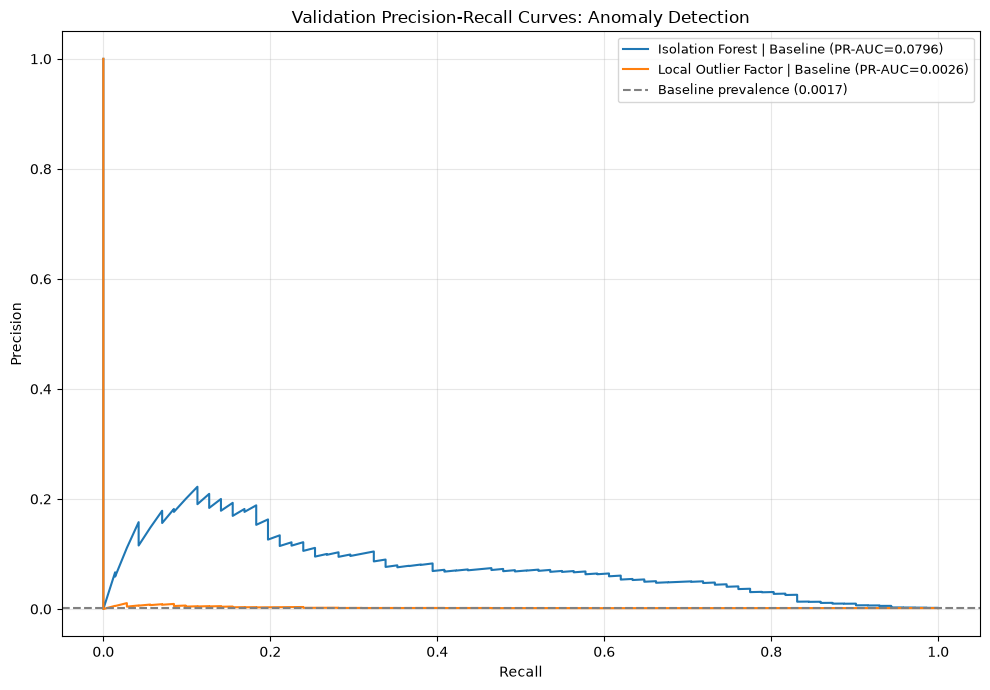

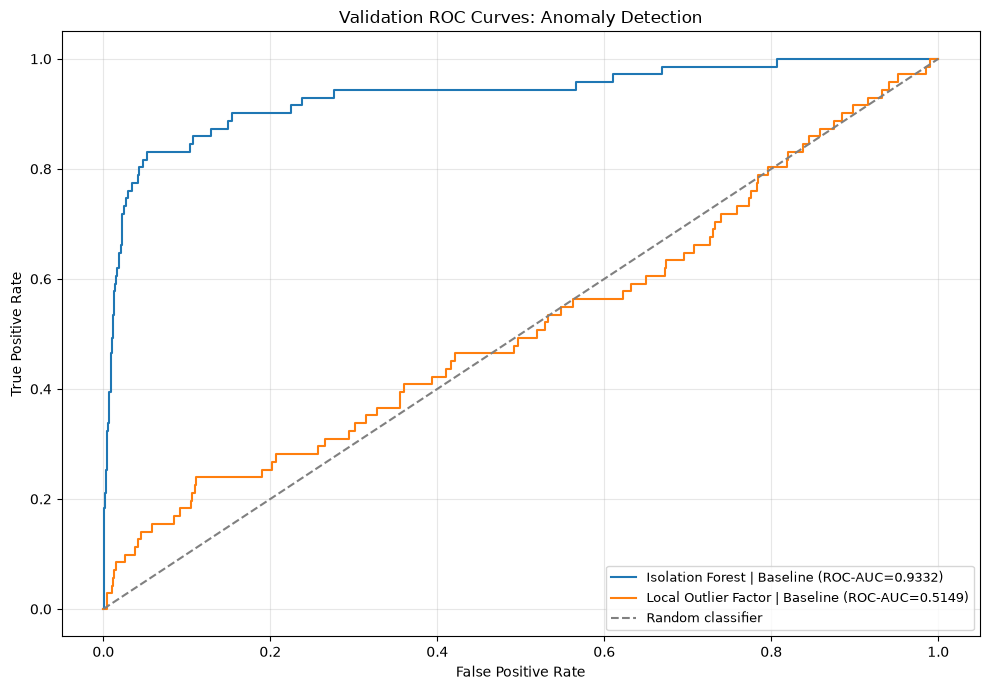

2026-11-01 10:54:34,962 | INFO | Anomaly-detection PR and ROC curves generated.


In [7]:
def plot_anomaly_precision_recall_curves(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation precision-recall curves for anomaly detectors."""
    plt.figure(figsize=(10, 7))

    for experiment_name, scores in scores_by_experiment.items():
        precision_values, recall_values, _ = precision_recall_curve(
            y_true,
            scores,
        )
        pr_auc = average_precision_score(y_true, scores)

        plt.plot(
            recall_values,
            precision_values,
            label=f"{experiment_name} (PR-AUC={pr_auc:.4f})",
        )

    fraud_prevalence = y_true.mean()
    plt.axhline(
        fraud_prevalence,
        color="gray",
        linestyle="--",
        label=f"Baseline prevalence ({fraud_prevalence:.4f})",
    )

    plt.title("Validation Precision-Recall Curves: Anomaly Detection")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(fontsize=9)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_anomaly_roc_curves(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation ROC curves for anomaly detectors."""
    plt.figure(figsize=(10, 7))

    for experiment_name, scores in scores_by_experiment.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            scores,
        )
        roc_auc = roc_auc_score(y_true, scores)

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{experiment_name} (ROC-AUC={roc_auc:.4f})",
        )

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")

    plt.title("Validation ROC Curves: Anomaly Detection")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=9)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


anomaly_pr_figure_path = FIGURES_DIR / "anomaly_precision_recall_curves.png"
anomaly_roc_figure_path = FIGURES_DIR / "anomaly_roc_curves.png"

plot_anomaly_precision_recall_curves(
    y_true=y_validation,
    scores_by_experiment=anomaly_scores_by_experiment,
    output_path=anomaly_pr_figure_path,
)

plot_anomaly_roc_curves(
    y_true=y_validation,
    scores_by_experiment=anomaly_scores_by_experiment,
    output_path=anomaly_roc_figure_path,
)

logger.info("Anomaly-detection PR and ROC curves generated.")

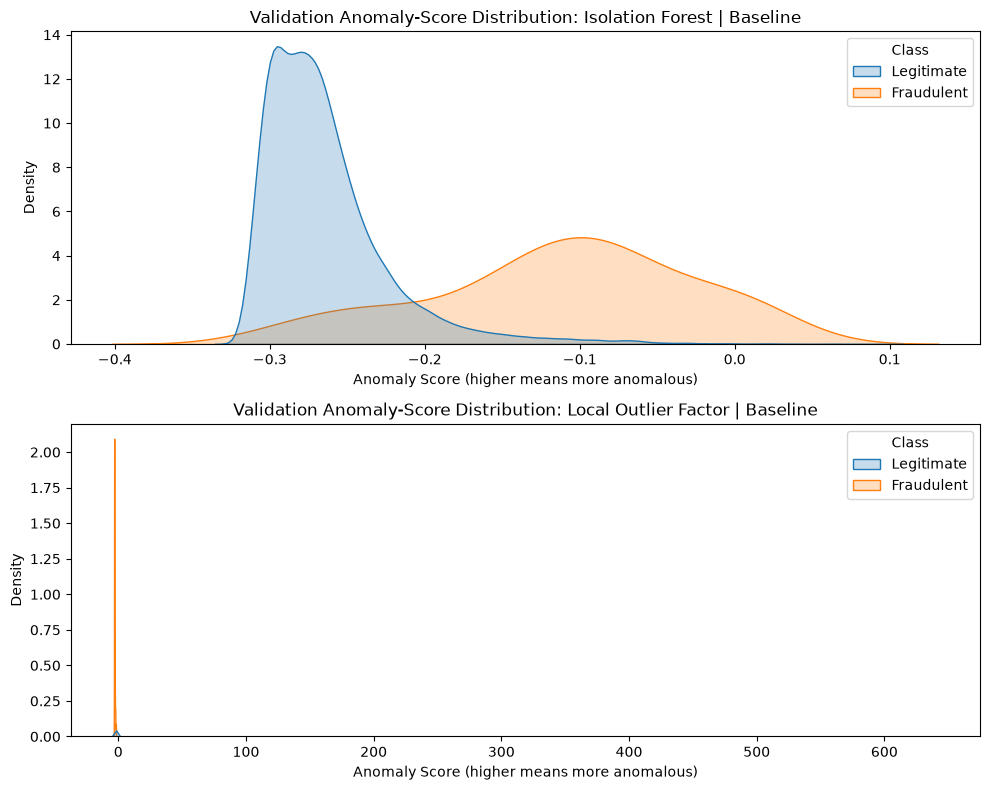

2026-11-01 10:54:59,434 | INFO | Anomaly-score distribution figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\anomaly_score_distributions.png


In [8]:
def plot_anomaly_score_distributions(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation anomaly-score distributions by actual fraud label."""
    experiment_names = list(scores_by_experiment)
    number_of_experiments = len(experiment_names)

    fig, axes = plt.subplots(
        number_of_experiments,
        1,
        figsize=(10, 4 * number_of_experiments),
        squeeze=False,
    )

    for axis, experiment_name in zip(axes.ravel(), experiment_names):
        scores = scores_by_experiment[experiment_name]

        plot_dataframe = pd.DataFrame(
            {
                "anomaly_score": scores,
                "Class": y_true.map({0: "Legitimate", 1: "Fraudulent"}).values,
            }
        )

        sns.kdeplot(
            data=plot_dataframe,
            x="anomaly_score",
            hue="Class",
            common_norm=False,
            fill=True,
            ax=axis,
        )
        axis.set_title(f"Validation Anomaly-Score Distribution: {experiment_name}")
        axis.set_xlabel("Anomaly Score (higher means more anomalous)")
        axis.set_ylabel("Density")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


anomaly_score_distribution_figure_path = (
    FIGURES_DIR / "anomaly_score_distributions.png"
)

plot_anomaly_score_distributions(
    y_true=y_validation,
    scores_by_experiment=anomaly_scores_by_experiment,
    output_path=anomaly_score_distribution_figure_path,
)

logger.info(
    "Anomaly-score distribution figure saved to: %s",
    anomaly_score_distribution_figure_path,
)

In [9]:
def save_anomaly_model_artifacts(
    experiment_name: str,
    pipeline: Pipeline,
    metrics: dict,
    output_directory: Path,
) -> dict:
    """Save one trained anomaly detector and its metadata."""
    safe_experiment_name = (
        experiment_name.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )

    experiment_directory = output_directory / safe_experiment_name
    experiment_directory.mkdir(parents=True, exist_ok=True)

    model_path = experiment_directory / "model.joblib"
    metadata_path = experiment_directory / "metadata.json"

    joblib.dump(pipeline, model_path)

    metadata = {
        "experiment_name": experiment_name,
        "model_name": metrics["model"],
        "model_type": "unsupervised_anomaly_detector",
        "feature_configuration": FEATURE_CONFIGURATION,
        "feature_columns": list(X_train_engineered.columns),
        "target_column": "Class",
        "target_used_during_training": False,
        "score_direction": metrics["score_direction"],
        "score_interpretation": (
            "Higher anomaly score means more anomalous; it is not a fraud probability."
        ),
        "random_seed": RANDOM_SEED,
        "preprocessing": metrics["preprocessing"],
        "validation_metrics": metrics,
        "artifact_note": (
            "This is a Phase 6 baseline anomaly-detection artifact, not the final production model."
        ),
    }

    with metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, default=str)

    return {
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    }


anomaly_artifact_paths = {}

for experiment_name, pipeline in trained_anomaly_pipelines.items():
    matching_result = anomaly_results_dataframe[
        anomaly_results_dataframe["experiment_name"] == experiment_name
    ].iloc[0].to_dict()

    anomaly_artifact_paths[experiment_name] = save_anomaly_model_artifacts(
        experiment_name=experiment_name,
        pipeline=pipeline,
        metrics=matching_result,
        output_directory=ANOMALY_MODELS_DIR,
    )

    logger.info(
        "Saved artifacts for %s: %s",
        experiment_name,
        anomaly_artifact_paths[experiment_name],
    )

2026-11-01 10:55:06,294 | INFO | Saved artifacts for Isolation Forest | Baseline: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\anomaly\\baseline_anomaly_models\\isolation_forest_baseline\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\anomaly\\baseline_anomaly_models\\isolation_forest_baseline\\metadata.json'}
2026-11-01 10:55:06,429 | INFO | Saved artifacts for Local Outlier Factor | Baseline: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\anomaly\\baseline_anomaly_models\\local_outlier_factor_baseline\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\anomaly\\baseline_anomaly_models\\local_outlier_factor_baseline\\metadata.json'}


In [10]:
def update_model_comparison_report(
    new_results: pd.DataFrame,
    comparison_path: Path,
) -> pd.DataFrame:
    """Append new experiment results to the existing comparison report."""
    if comparison_path.exists():
        existing_results = pd.read_csv(comparison_path)
    else:
        existing_results = pd.DataFrame()

    new_result_columns = list(new_results.columns)

    if not existing_results.empty:
        missing_columns = set(new_result_columns) - set(existing_results.columns)
        for column in missing_columns:
            existing_results[column] = np.nan

    combined_results = pd.concat(
        [existing_results[new_result_columns], new_results[new_result_columns]],
        ignore_index=True,
    )

    combined_results.to_csv(comparison_path, index=False)
    return combined_results


model_comparison_path = REPORTS_DIR / "model_comparison.csv"

updated_model_comparison = update_model_comparison_report(
    new_results=anomaly_results_dataframe,
    comparison_path=model_comparison_path,
)

logger.info(
    "Updated model comparison report: %s rows",
    len(updated_model_comparison),
)

2026-11-01 10:55:12,799 | INFO | Updated model comparison report: 13 rows


In [11]:
def write_anomaly_detection_report(
    results_dataframe: pd.DataFrame,
    report_path: Path,
) -> None:
    """Write a concise anomaly-detection evaluation report."""
    report_lines = [
        "# Anomaly Detection Experiment Results",
        "",
        "## Scope",
        "",
        f"- Feature configuration: `{FEATURE_CONFIGURATION}`",
        "- Training data: Training features only",
        "- Evaluation dataset: Validation set",
        "- Fraud labels: Used only for evaluation, not training",
        "- Test set: Not used in this phase",
        "- Score convention: Higher anomaly score means more anomalous",
        "- Anomaly score is not a fraud probability",
        "",
        "## Validation Results",
        "",
    ]

    for _, row in results_dataframe.iterrows():
        report_lines.extend(
            [
                f"### {row['experiment_name']}",
                "",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- PR-AUC: {row['pr_auc']:.4f}",
                f"- ROC-AUC: {row['roc_auc']:.4f}",
                f"- False-positive rate: {row['false_positive_rate']:.6f}",
                f"- Transactions flagged: {row['transactions_flagged']:,}",
                f"- True positives: {row['true_positives']}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']}",
                f"- Training duration: {row['training_duration_seconds']:.2f} seconds",
                f"- Preprocessing: {row['preprocessing']}",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Interpretation",
            "",
            "- These are validation results, not final generalization estimates.",
            "- Anomaly detectors identify unusual transactions, not confirmed fraud.",
            "- PR-AUC is the primary ranking metric because fraud is extremely rare.",
            "- The contamination parameter controls the initial anomaly-flagging rate but does not define the true fraud rate.",
            "- The untouched test set remains reserved for final evaluation.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")


anomaly_detection_report_path = REPORTS_DIR / "anomaly_detection_report.md"

write_anomaly_detection_report(
    results_dataframe=anomaly_results_dataframe,
    report_path=anomaly_detection_report_path,
)

logger.info(
    "Anomaly-detection report saved to: %s",
    anomaly_detection_report_path,
)

2026-11-01 10:55:20,534 | INFO | Anomaly-detection report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\anomaly_detection_report.md


In [12]:
required_anomaly_artifacts = [
    anomaly_pr_figure_path,
    anomaly_roc_figure_path,
    anomaly_score_distribution_figure_path,
    anomaly_detection_report_path,
    model_comparison_path,
]

for artifact_paths in anomaly_artifact_paths.values():
    required_anomaly_artifacts.extend(
        [
            Path(artifact_paths["model_path"]),
            Path(artifact_paths["metadata_path"]),
        ]
    )

missing_artifacts = [
    path for path in required_anomaly_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing Phase 6 anomaly artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required Phase 6 anomaly artifacts were generated successfully.")
print("Phase 6 anomaly detection completed successfully.")

2026-11-01 10:55:29,302 | INFO | All required Phase 6 anomaly artifacts were generated successfully.


Phase 6 anomaly detection completed successfully.
